# Bike Sharing Demand Analysis

**Research question:** How do season, weather conditions, and temperature relate to daily bike-sharing demand?

This notebook uses the daily file (`day.csv`) from the [UCI Bike Sharing Dataset](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset). It downloads the data, checks and prepares it, explores rental patterns, and saves visualizations to `figures/` for the GitHub project repository.

In [1]:
from pathlib import Path
import urllib.request
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data"
FIGURES_DIR = ROOT / "figures"
DATA_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

ZIP_PATH = DATA_DIR / "bike_sharing_dataset.zip"
DATA_URL = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
DAY_PATH = next(DATA_DIR.rglob("day.csv"), None)

if DAY_PATH is None:
    if not ZIP_PATH.exists():
        print("Downloading the UCI dataset...")
        urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH) as archive:
        archive.extractall(DATA_DIR)
    DAY_PATH = next(DATA_DIR.rglob("day.csv"), None)

assert DAY_PATH is not None, f"Dataset file not found under: {DATA_DIR}"
print(f"Dataset ready: {DAY_PATH.name}")

Dataset ready: day.csv


## 1. Load and Inspect the Data

In [2]:
df = pd.read_csv(DAY_PATH, parse_dates=["dteday"])
df = df.rename(columns={"dteday": "date", "cnt": "total_rentals"})

season_labels = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
weather_labels = {
    1: "Clear / partly cloudy",
    2: "Mist / cloudy",
    3: "Light rain / snow",
    4: "Heavy rain / snow",
}
df["season_name"] = df["season"].map(season_labels)
df["weather_name"] = df["weathersit"].map(weather_labels)
df["year"] = df["date"].dt.year
df["month_name"] = df["date"].dt.strftime("%b")

print(f"Rows: {len(df):,}")
print(f"Date range: {df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
display(df.head())
display(df[["date", "season_name", "weather_name", "temp", "atemp", "total_rentals"]].describe(include="all"))

Rows: 731
Date range: 2011-01-01 to 2012-12-31


,instant,date,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,total_rentals,season_name,weather_name,year,month_name
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985,Spring,Mist / cloudy,2011,Jan
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801,Spring,Mist / cloudy,2011,Jan
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349,Spring,Clear / partly cloudy,2011,Jan
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562,Spring,Clear / partly cloudy,2011,Jan
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600,Spring,Clear / partly cloudy,2011,Jan


,date,season_name,weather_name,temp,atemp,total_rentals
count,731,731,731,731.000000,731.000000,731.000000
unique,NaN,4,3,NaN,NaN,NaN
top,NaN,Fall,Clear / partly cloudy,NaN,NaN,NaN
freq,NaN,188,463,NaN,NaN,NaN
mean,2012-01-01 00:00:00,NaN,NaN,0.495385,0.474354,4504.348837
min,2011-01-01 00:00:00,NaN,NaN,0.059130,0.079070,22.000000
25%,2011-07-02 12:00:00,NaN,NaN,0.337083,0.337842,3152.000000
50%,2012-01-01 00:00:00,NaN,NaN,0.498333,0.486733,4548.000000
75%,2012-07-01 12:00:00,NaN,NaN,0.655417,0.608602,5956.000000
max,2012-12-31 00:00:00,NaN,NaN,0.861667,0.840896,8714.000000


## 2. Data Quality Checks

The `temp`, `atemp`, `hum`, and `windspeed` columns are normalized values in the UCI dataset. We check for missing values, duplicate rows, and plausible rental counts.

In [3]:
quality = pd.DataFrame({
    "missing_values": df.isna().sum(),
    "duplicate_values": df.duplicated().sum()
})
display(quality[quality["missing_values"] > 0])
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Minimum daily rentals: {df['total_rentals'].min():,}")
print(f"Maximum daily rentals: {df['total_rentals'].max():,}")

assert df["total_rentals"].ge(0).all(), "Rental counts must be non-negative."
assert df["date"].is_monotonic_increasing, "Dates should be in chronological order."

,missing_values,duplicate_values


Duplicate rows: 0
Minimum daily rentals: 22
Maximum daily rentals: 8,714


## 3. Monthly Rental Patterns

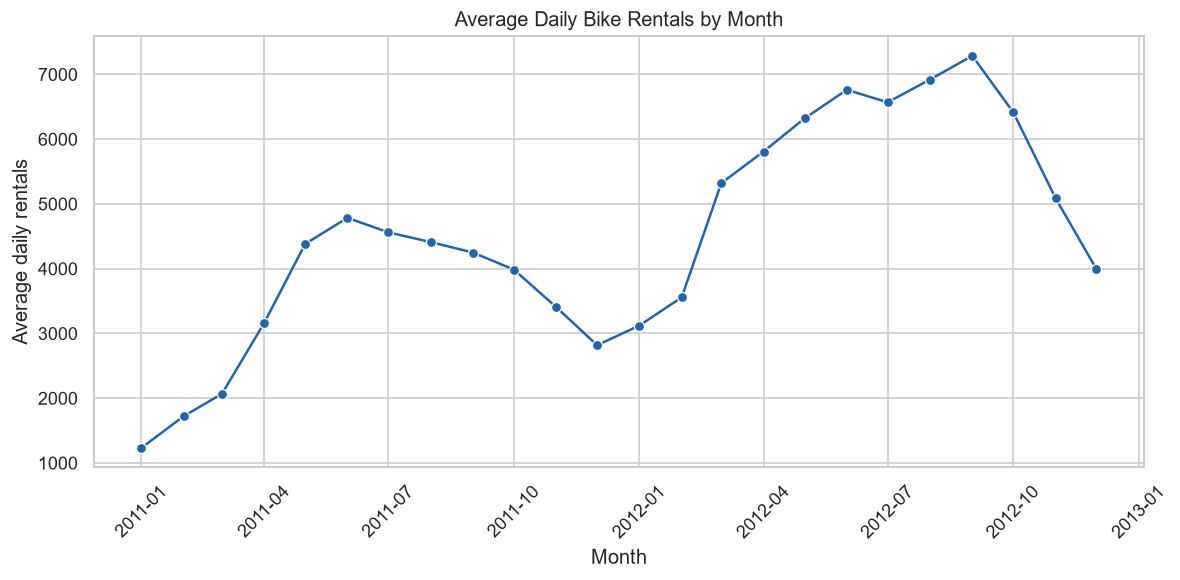

Highest monthly average: September 2012 (7,286 rentals/day)
Lowest monthly average: January 2011 (1,232 rentals/day)


In [4]:
monthly = (
    df.set_index("date")["total_rentals"]
      .resample("MS")
      .mean()
      .reset_index(name="mean_daily_rentals")
)

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=monthly, x="date", y="mean_daily_rentals", marker="o", ax=ax, color="#2166ac")
ax.set(title="Average Daily Bike Rentals by Month", xlabel="Month", ylabel="Average daily rentals")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "monthly_rentals.png", dpi=180, bbox_inches="tight")
plt.show()

peak_month = monthly.loc[monthly["mean_daily_rentals"].idxmax()]
low_month = monthly.loc[monthly["mean_daily_rentals"].idxmin()]
print(f"Highest monthly average: {peak_month['date']:%B %Y} ({peak_month['mean_daily_rentals']:,.0f} rentals/day)")
print(f"Lowest monthly average: {low_month['date']:%B %Y} ({low_month['mean_daily_rentals']:,.0f} rentals/day)")

## 4. Feeling Temperature and Rental Demand

`atemp` is the normalized feeling temperature. Points are colored by season to show seasonal variation alongside the overall pattern.

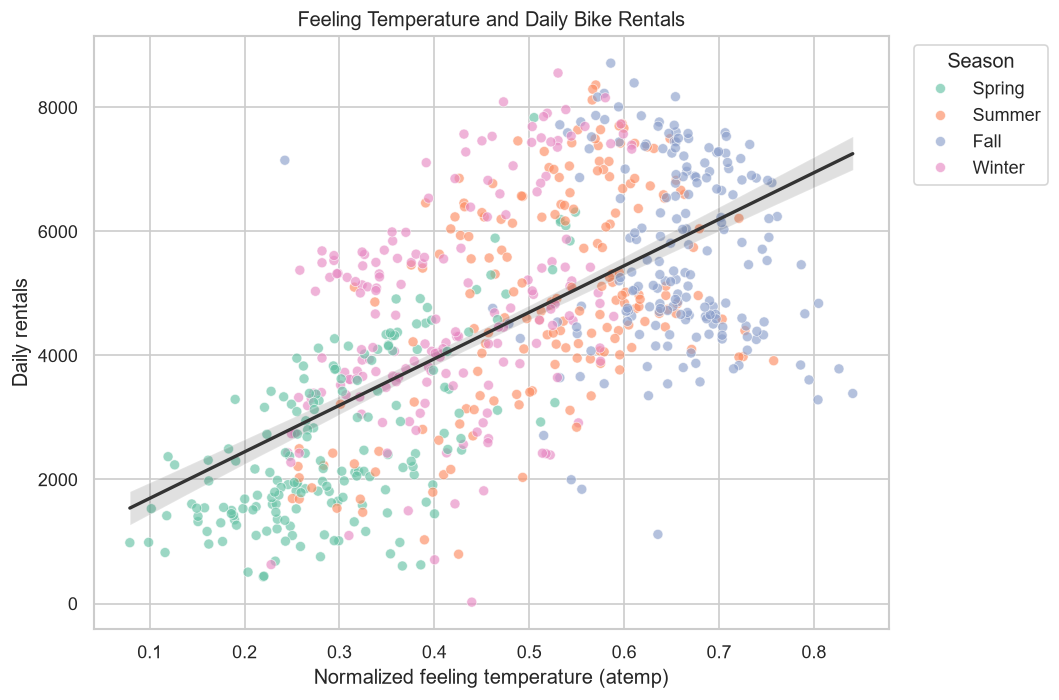

Pearson correlation between feeling temperature and rentals: 0.63


In [5]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(
    data=df, x="atemp", y="total_rentals", hue="season_name",
    hue_order=["Spring", "Summer", "Fall", "Winter"],
    alpha=0.65, palette="Set2", ax=ax
)
sns.regplot(data=df, x="atemp", y="total_rentals", scatter=False, color="#333333", ax=ax, line_kws={"lw": 2, "label": "Overall trend"})
ax.set(title="Feeling Temperature and Daily Bike Rentals", xlabel="Normalized feeling temperature (atemp)", ylabel="Daily rentals")
ax.legend(title="Season", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "temperature_vs_rentals.png", dpi=180, bbox_inches="tight")
plt.show()

correlation = df[["atemp", "total_rentals"]].corr().iloc[0, 1]
print(f"Pearson correlation between feeling temperature and rentals: {correlation:.2f}")

## 5. Comparing Weather Conditions

,weather_name,mean_daily_rentals
0,Clear / partly cloudy,4876.786177
2,Mist / cloudy,4035.862348
1,Light rain / snow,1803.285714


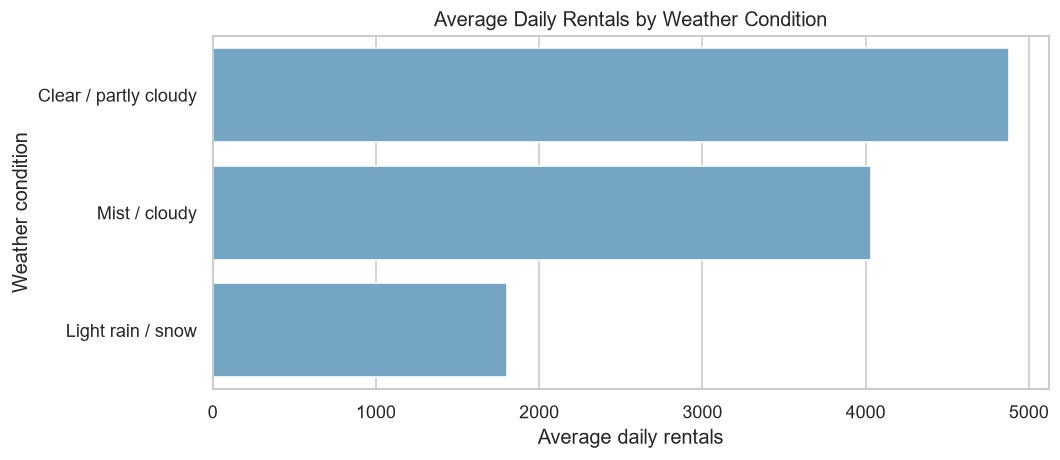

In [6]:
weather_summary = (
    df.groupby("weather_name", as_index=False)["total_rentals"]
      .mean()
      .sort_values("total_rentals", ascending=False)
)
display(weather_summary.rename(columns={"total_rentals": "mean_daily_rentals"}))

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=weather_summary, x="total_rentals", y="weather_name", color="#67a9cf", ax=ax)
ax.set(title="Average Daily Rentals by Weather Condition", xlabel="Average daily rentals", ylabel="Weather condition")
fig.tight_layout()
plt.show()

## 6. Summary of Results for the README

The following summary is generated from the results calculated in this notebook. Use these observed results in the GitHub `README.md`.

In [7]:
strongest_season = df.groupby("season_name")["total_rentals"].mean().sort_values(ascending=False)
strongest_weather = weather_summary.iloc[0]
weakest_weather = weather_summary.iloc[-1]
print(
    f"The highest monthly average was in {peak_month['date']:%B %Y} "
    f"({peak_month['mean_daily_rentals']:,.0f} rentals/day); the lowest was in {low_month['date']:%B %Y} "
    f"({low_month['mean_daily_rentals']:,.0f} rentals/day)."
)
print(
    f"The Pearson correlation between feeling temperature and daily rentals was {correlation:.2f}. "
    "This indicates an association, but it does not prove that temperature caused the change in rentals."
)
print(
    f"The highest average rentals occurred in {strongest_weather['weather_name']} "
    f"({strongest_weather['total_rentals']:,.0f} per day); the lowest occurred in {weakest_weather['weather_name']} "
    f"({weakest_weather['total_rentals']:,.0f} per day)."
)
print("Limitation: This is observational data from one bike-sharing system over a limited period, so the findings may not generalize to other cities or time periods.")

The highest monthly average was in September 2012 (7,286 rentals/day); the lowest was in January 2011 (1,232 rentals/day).
The Pearson correlation between feeling temperature and daily rentals was 0.63. This indicates an association, but it does not prove that temperature caused the change in rentals.
The highest average rentals occurred in Clear / partly cloudy (4,877 per day); the lowest occurred in Light rain / snow (1,803 per day).
Limitation: This is observational data from one bike-sharing system over a limited period, so the findings may not generalize to other cities or time periods.


## 7. Next Steps

- Compare rentals across weekdays, working days, and holidays.
- Use the hourly dataset to study commute and peak-hour patterns.
- If building a predictive model, use separate training and test sets and report appropriate error metrics.
- Upload `figures/monthly_rentals.png` and `figures/temperature_vs_rentals.png` to the `data-science-project` repository.